# ML_79 — Monitoring a Financial Fraud Detection Model

### Machine Learning Lab · Experiment 11: Industry-Based Case Study
**B.Tech CSE (IoT) · Semester V · SKIT Jaipur**

---

### Project Team Details

- **Team ID:** G58
- **Student 1:** Tanish Pinjani (24ESKCY054)
- **Student 2:** Vanshika Jain (24ESKCY059)
- **Project ID:** ML_79
- **Project Name:** Monitoring a Financial Fraud Detection Model
- **Lab:** Machine Learning
- **Course Code:** 5CIUP521

---

## Project Overview

Financial fraud detection is an important application of machine learning in the banking and financial industry. Every day, financial institutions process thousands of transactions, and identifying fraudulent activities accurately is essential for protecting customers and preventing financial losses.

This project focuses on developing a machine learning model to detect potentially fraudulent credit card transactions and monitoring its performance after deployment.

The project also examines how changes in transaction data can affect model predictions and reliability over time.

## Project Objectives

1. Develop a machine learning model to classify legitimate and fraudulent transactions.
2. Evaluate model performance using precision, recall, F1-score and other evaluation metrics.
3. Monitor incoming transaction data to identify data drift.
4. Analyse possible concept drift and changes in model performance.
5. Identify transaction groups with unusually high false-positive rates.
6. Demonstrate model monitoring, alert generation and retraining.

## Project Methodology

The project follows these major stages:

1. Dataset loading and exploratory data analysis.
2. Data preprocessing and feature engineering.
3. Training and comparison of machine learning algorithms.
4. Selection and evaluation of the best-performing model.
5. Simulation of post-deployment transaction monitoring.
6. Data drift and possible concept drift detection.
7. False-positive analysis and monitoring alerts.
8. Model retraining and performance comparison.


## Expected Outcome

The final system demonstrates how a financial fraud detection model can be monitored after deployment. It evaluates model performance, identifies changes in transaction patterns, detects possible performance degradation and highlights unusual false-positive behaviour.

The monitoring experiments use historical transaction data and simulated changes to demonstrate real-world monitoring concepts.


## System architecture

The workflow starts with historical transactions, trains and evaluates a fraud classifier, then simulates incoming transaction windows. Three monitoring checks examine feature distributions, model performance, and false-positive rates for transaction slices. An alert summary combines their findings; a retraining experiment illustrates one possible response.


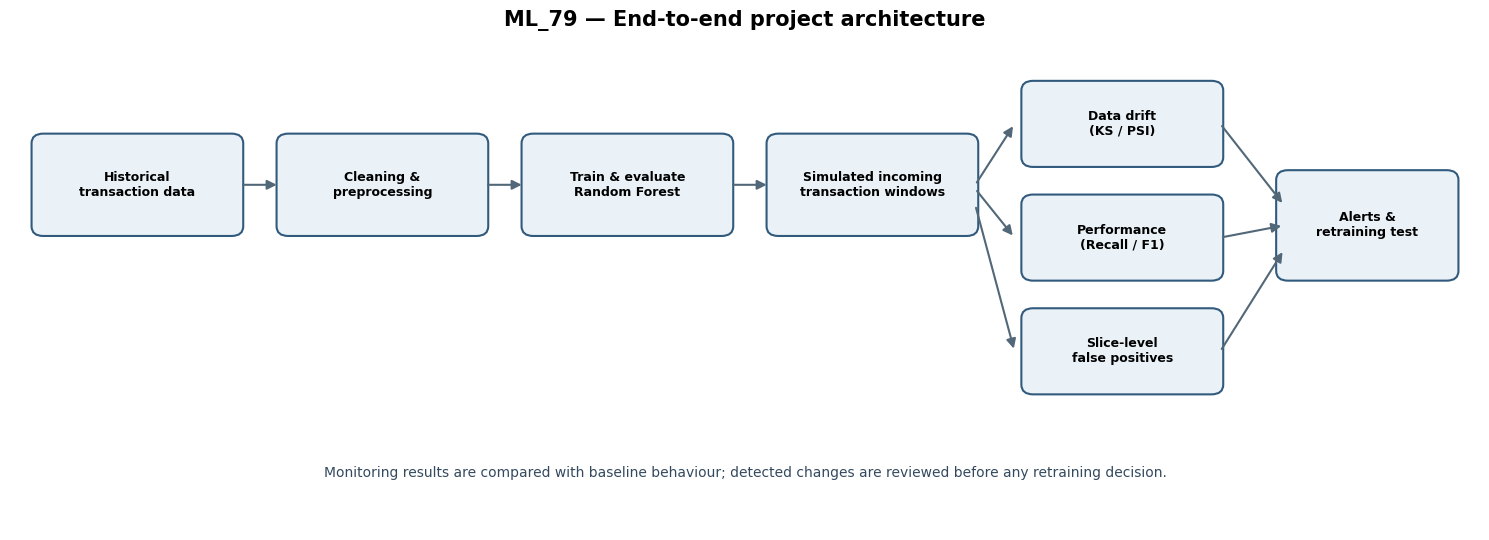

In [1]:
# Visual overview of the complete project workflow
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

fig, ax = plt.subplots(figsize=(15, 5.5))
ax.set_xlim(0, 15); ax.set_ylim(0, 6); ax.axis("off")

nodes = [
    (0.3, 3.7, 2.0, 1.1, "Historical\ntransaction data"),
    (2.8, 3.7, 2.0, 1.1, "Cleaning &\npreprocessing"),
    (5.3, 3.7, 2.0, 1.1, "Train & evaluate\nRandom Forest"),
    (7.8, 3.7, 2.0, 1.1, "Simulated incoming\ntransaction windows"),
    (10.4, 4.55, 1.9, 0.9, "Data drift\n(KS / PSI)"),
    (10.4, 3.15, 1.9, 0.9, "Performance\n(Recall / F1)"),
    (10.4, 1.75, 1.9, 0.9, "Slice-level\nfalse positives"),
    (13.0, 3.15, 1.7, 1.2, "Alerts &\nretraining test"),
]
for x,y,w,h,label in nodes:
    box=FancyBboxPatch((x,y),w,h,boxstyle="round,pad=0.08,rounding_size=0.12",fc="#EAF2F8",ec="#315A7D",lw=1.5)
    ax.add_patch(box); ax.text(x+w/2,y+h/2,label,ha="center",va="center",fontsize=9,weight="bold")

def arrow(a,b):
    ax.add_patch(FancyArrowPatch(a,b,arrowstyle="-|>",mutation_scale=14,lw=1.5,color="#526777"))
arrow((2.35,4.25),(2.75,4.25)); arrow((4.85,4.25),(5.25,4.25)); arrow((7.35,4.25),(7.75,4.25))
arrow((9.85,4.25),(10.25,5.0)); arrow((9.85,4.2),(10.25,3.6)); arrow((9.85,4.0),(10.25,2.2))
arrow((12.35,5.0),(13.0,4.0)); arrow((12.35,3.6),(13.0,3.75)); arrow((12.35,2.2),(13.0,3.45))
ax.text(7.5,0.65,"Monitoring results are compared with baseline behaviour; detected changes are reviewed before any retraining decision.",ha="center",fontsize=10,color="#34495E")
ax.set_title("ML_79 — End-to-end project architecture",fontsize=15,weight="bold",pad=12)
plt.tight_layout(); plt.show()


In [2]:
# ===== Setup: import all libraries we need =====
import os
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import ks_2samp

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, ConfusionMatrixDisplay)
import joblib

warnings.filterwarnings("ignore")          # hide harmless library warnings
RANDOM_STATE = 42                          # same random numbers every run
np.random.seed(RANDOM_STATE)
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)
plt.rcParams["figure.figsize"] = (10, 4)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3
print("All libraries loaded.")

All libraries loaded.


## Phase 1 — Load and understand the data (Exp 1)

In [3]:
DATA_FILE = "creditcard.csv"
DATA_URL = "https://storage.googleapis.com/download.tensorflow.org/data/creditcard.csv"
USE_SYNTHETIC = False   # set to True to skip the real data and use fake data instead


def make_synthetic_data(n_rows=100_000, seed=RANDOM_STATE):
    """Fallback: create a fake dataset with the same columns as creditcard.csv."""
    from sklearn.datasets import make_classification
    X, y = make_classification(n_samples=n_rows, n_features=28, n_informative=12,
                               n_redundant=4, weights=[0.998], flip_y=0,
                               class_sep=2.0, random_state=seed)
    data = pd.DataFrame(X, columns=[f"V{i}" for i in range(1, 29)])
    rng = np.random.default_rng(seed)
    data.insert(0, "Time", np.sort(rng.uniform(0, 172_792, n_rows)).round())  # 2 days
    data["Amount"] = np.round(rng.lognormal(3.0, 1.3, n_rows), 2)            # skewed like real money
    data["Class"] = y
    return data


# Try to download the real file if it is not already here
if not USE_SYNTHETIC and not os.path.exists(DATA_FILE):
    try:
        import urllib.request
        print("Downloading creditcard.csv (about 150 MB)...")
        urllib.request.urlretrieve(DATA_URL, DATA_FILE)
    except Exception as error:
        print("Download failed:", error)

if not USE_SYNTHETIC and os.path.exists(DATA_FILE):
    df = pd.read_csv(DATA_FILE)
    DATA_SOURCE = "real Kaggle data"
else:
    df = make_synthetic_data()
    DATA_SOURCE = "SYNTHETIC data (fallback)"

print("Using:", DATA_SOURCE)
print("Shape (rows, columns):", df.shape)
df.head()

Using: real Kaggle data
Shape (rows, columns): (284807, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,V12,V13,V14,V15,V16,V17,V18,V19,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,0.090794,-0.551600,-0.617801,-0.991390,-0.311169,1.468177,-0.470401,0.207971,0.025791,0.403993,0.251412,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,-0.166974,1.612727,1.065235,0.489095,-0.143772,0.635558,0.463917,-0.114805,-0.183361,-0.145783,-0.069083,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,0.207643,0.624501,0.066084,0.717293,-0.165946,2.345865,-2.890083,1.109969,-0.121359,-2.261857,0.524980,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,-0.054952,-0.226487,0.178228,0.507757,-0.287924,-0.631418,-1.059647,-0.684093,1.965775,-1.232622,-0.208038,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,0.753074,-0.822843,0.538196,1.345852,-1.119670,0.175121,-0.451449,-0.237033,-0.038195,0.803487,0.408542,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [4]:
# Column types and memory use
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     28

In [5]:
# Basic statistics of a few important columns
df[["Time", "V1", "V2", "V3", "V4", "Amount", "Class"]].describe().round(3)

,Time,V1,V2,V3,V4,Amount,Class
count,284807.000,284807.000,284807.000,284807.000,284807.000,284807.000,284807.000
mean,94813.860,0.000,0.000,-0.000,0.000,88.350,0.002
std,47488.146,1.959,1.651,1.516,1.416,250.120,0.042
min,0.000,-56.408,-72.716,-48.326,-5.683,0.000,0.000
25%,54201.500,-0.920,-0.599,-0.890,-0.849,5.600,0.000
50%,84692.000,0.018,0.065,0.180,-0.020,22.000,0.000
75%,139320.500,1.316,0.804,1.027,0.743,77.165,0.000
max,172792.000,2.455,22.058,9.383,16.875,25691.160,1.000


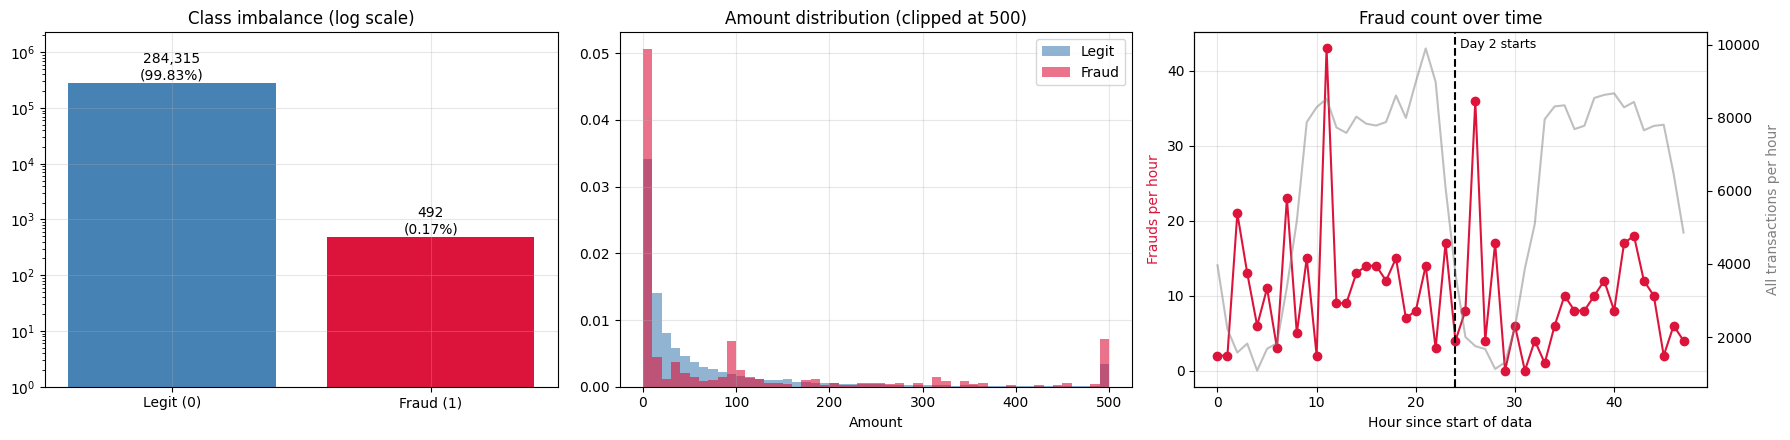

Fraud rate: 0.1727%  ->  about 1 fraud in every 578 transactions


In [6]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))

# (a) Class imbalance: how many legit vs fraud transactions
counts = df["Class"].value_counts().sort_index()
axes[0].bar(["Legit (0)", "Fraud (1)"], counts.values, color=["steelblue", "crimson"])
axes[0].set_yscale("log")
axes[0].set_title("Class imbalance (log scale)")
for i, value in enumerate(counts.values):
    axes[0].text(i, value, f"{value:,}\n({value / len(df):.2%})", ha="center", va="bottom")
axes[0].set_ylim(1, counts.max() * 8)

# (b) Amount distribution for each class (clipped at 500 so the plot is readable)
axes[1].hist(df.loc[df.Class == 0, "Amount"].clip(upper=500), bins=50, alpha=0.6,
             density=True, label="Legit", color="steelblue")
axes[1].hist(df.loc[df.Class == 1, "Amount"].clip(upper=500), bins=50, alpha=0.6,
             density=True, label="Fraud", color="crimson")
axes[1].set_title("Amount distribution (clipped at 500)")
axes[1].set_xlabel("Amount")
axes[1].legend()

# (c) Fraud count and total transactions for every hour of the 2 days
hour_of_data = (df["Time"] // 3600).astype(int)
fraud_per_hour = df[df.Class == 1].groupby(hour_of_data[df.Class == 1]).size().reindex(range(48), fill_value=0)
all_per_hour = df.groupby(hour_of_data).size().reindex(range(48), fill_value=0)
axes[2].plot(fraud_per_hour.index, fraud_per_hour.values, marker="o", color="crimson", label="Frauds")
axes[2].set_ylabel("Frauds per hour", color="crimson")
twin = axes[2].twinx()
twin.plot(all_per_hour.index, all_per_hour.values, color="gray", alpha=0.5, label="All transactions")
twin.set_ylabel("All transactions per hour", color="gray")
twin.grid(False)
axes[2].axvline(24, color="black", linestyle="--")
axes[2].text(24.5, fraud_per_hour.max(), "Day 2 starts", fontsize=9)
axes[2].set_title("Fraud count over time")
axes[2].set_xlabel("Hour since start of data")

plt.tight_layout()
plt.show()

print(f"Fraud rate: {df['Class'].mean():.4%}  ->  about 1 fraud in every {int(1 / df['Class'].mean())} transactions")

**What this tells us:** The dataset is strongly imbalanced: fraud is a very small fraction of all transactions. A classifier can therefore show high accuracy while missing fraud. We will focus on precision, recall, F1-score and false-positive rate.

## Phase 2 — Preprocessing (Exp 2)

In [7]:
# 1. Missing values
print("Total missing values:", df.isnull().sum().sum())

# 2. Duplicate rows (same transaction recorded twice)
n_duplicates = df.duplicated().sum()
print("Duplicate rows found:", n_duplicates)
df = df.drop_duplicates().reset_index(drop=True)
print("Shape after removing duplicates:", df.shape)

Total missing values: 0
Duplicate rows found: 1081
Shape after removing duplicates: (283726, 31)


In [8]:
SPLIT_TIME = 24 * 3600                       # first 24 hours = training, last 24 hours = live
V_COLS = [f"V{i}" for i in range(1, 29)]


def add_slice_features(data):
    """Add Hour, Period (Day/Night) and Amount_band columns."""
    data = data.copy()
    data["Hour"] = ((data["Time"] // 3600) % 24).astype(int)
    data["Period"] = np.where(data["Hour"] < 7, "Night", "Day")
    data["Amount_band"] = pd.cut(data["Amount"], bins=[-np.inf, 20, 100, np.inf],
                                 labels=["Low", "Medium", "High"]).astype(str)
    return data


# Fit the scalers on the TRAINING day only (avoids data leakage)
train_rows = df["Time"] < SPLIT_TIME
amount_scaler = StandardScaler().fit(df.loc[train_rows, ["Amount"]])
time_scaler = StandardScaler().fit(df.loc[train_rows, ["Time"]])


def add_scaled_features(data):
    """Scale Amount and Time to mean 0, standard deviation 1 (using training statistics)."""
    data = data.copy()
    data["Amount_scaled"] = amount_scaler.transform(data[["Amount"]]).ravel()
    data["Time_scaled"] = time_scaler.transform(data[["Time"]]).ravel()
    return data


df = add_slice_features(df)
df = add_scaled_features(df)

# Simple label encoding of the Amount band (Low=0, Medium=1, High=2), shown as an encoding example
df["Amount_band_code"] = df["Amount_band"].map({"Low": 0, "Medium": 1, "High": 2})

df[["Time", "Time_scaled", "Hour", "Period", "Amount", "Amount_scaled", "Amount_band", "Amount_band_code"]].head(8)

,Time,Time_scaled,Hour,Period,Amount,Amount_scaled,Amount_band,Amount_band_code
0,0.0,-2.480484,0,Night,149.62,0.239853,High,2
1,0.0,-2.480484,0,Night,2.69,-0.356860,Low,0
2,1.0,-2.480437,0,Night,378.66,1.170030,High,2
3,1.0,-2.480437,0,Night,123.50,0.133774,High,2
4,2.0,-2.480390,0,Night,69.99,-0.083541,Medium,1
5,2.0,-2.480390,0,Night,3.67,-0.352880,Low,0
6,4.0,-2.480296,0,Night,4.99,-0.347519,Low,0
7,7.0,-2.480156,0,Night,40.80,-0.202087,Medium,1


In [9]:
print("Rows per Amount band:\n", df["Amount_band"].value_counts(), "\n")
print("Rows per Period:\n", df["Period"].value_counts(), "\n")

# Features given to the models: V1..V28 + scaled Amount.
# Time is NOT used as a model input: with a time-based split, every live transaction has a
# larger Time than anything seen in training, so the model could not use it sensibly.
FEATURES = V_COLS + ["Amount_scaled"]
print("Number of model features:", len(FEATURES))

Rows per Amount band:
 Amount_band
Low       138489
Medium     88838
High       56399
Name: count, dtype: int64 

Rows per Period:
 Period
Day      255802
Night     27924
Name: count, dtype: int64 

Number of model features: 29


**Preprocessing result:** Missing values and duplicate rows are checked before modelling. The notebook creates readable time/amount slices for monitoring and scales Amount and Time using training-period statistics.

## Phase 3 — Train and compare models (Exp 3–7, optional 10)

In [10]:
train_df = df[df["Time"] < SPLIT_TIME].copy()     # Day 1
live_df = df[df["Time"] >= SPLIT_TIME].copy()     # Day 2 (the "future")

print(f"Training day : {len(train_df):,} rows, {train_df['Class'].sum()} frauds")
print(f"Live day     : {len(live_df):,} rows, {live_df['Class'].sum()} frauds")

# Validation split INSIDE the training day (stratify keeps the same fraud % in both parts)
fit_df, val_df = train_test_split(train_df, test_size=0.25, stratify=train_df["Class"],
                                  random_state=RANDOM_STATE)
X_fit, y_fit = fit_df[FEATURES], fit_df["Class"]
X_val, y_val = val_df[FEATURES], val_df["Class"]
print(f"Model fitting part: {len(fit_df):,} rows | validation part: {len(val_df):,} rows")

Training day : 144,236 rows, 272 frauds
Live day     : 139,490 rows, 201 frauds
Model fitting part: 108,177 rows | validation part: 36,059 rows


In [11]:
def get_metrics(y_true, y_pred):
    """Return the metrics we care about as a dictionary."""
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),  # of all alerts, how many were real fraud
        "Recall": recall_score(y_true, y_pred, zero_division=0),        # of all frauds, how many we caught
        "F1": f1_score(y_true, y_pred, zero_division=0),                # balance of precision and recall
        "FPR": fp / (fp + tn) if (fp + tn) > 0 else 0.0,                # legit customers wrongly flagged
        "Alert_rate": float(np.mean(y_pred)),                           # share of transactions flagged
        "TP": tp, "FP": fp, "FN": fn, "TN": tn,
    }


results, trained = {}, {}

def train_and_score(name, model, X, y):
    start = time.time()
    model.fit(X, y)
    results[name] = get_metrics(y_val, model.predict(X_val))
    trained[name] = model
    print(f"{name:<24} trained in {time.time() - start:6.1f}s  |  F1 = {results[name]['F1']:.3f}")

In [12]:
# Exp 3 - Logistic Regression (linear model + sigmoid)
train_and_score("Logistic Regression", LogisticRegression(max_iter=1000), X_fit, y_fit)

# Exp 4 - KNN: slow on big data, so we train it on a stratified sample of 40,000 rows
knn_sample, _ = train_test_split(fit_df, train_size=min(40_000, int(len(fit_df) * 0.9)), stratify=fit_df["Class"], random_state=RANDOM_STATE)
train_and_score("KNN (k=5)", KNeighborsClassifier(n_neighbors=5), knn_sample[FEATURES], knn_sample["Class"])

# Exp 5 - Gaussian Naive Bayes
train_and_score("Naive Bayes", GaussianNB(), X_fit, y_fit)

# Exp 6 - Decision Tree (depth limited to avoid overfitting)
train_and_score("Decision Tree", DecisionTreeClassifier(max_depth=8, random_state=RANDOM_STATE), X_fit, y_fit)

# Exp 7 - Random Forest with different numbers of trees
for n_trees in [50, 100, 200]:
    train_and_score(f"Random Forest ({n_trees})",
                    RandomForestClassifier(n_estimators=n_trees, n_jobs=-1, random_state=RANDOM_STATE),
                    X_fit, y_fit)

# Optional - SVM (RBF kernel) on a small sample of 15,000 rows because SVM is slow
svm_sample, _ = train_test_split(fit_df, train_size=min(15_000, int(len(fit_df) * 0.5)), stratify=fit_df["Class"], random_state=RANDOM_STATE)
train_and_score("SVM (sample)", SVC(kernel="rbf", C=10), svm_sample[FEATURES], svm_sample["Class"])

Logistic Regression      trained in    1.0s  |  F1 = 0.690
KNN (k=5)                trained in   13.7s  |  F1 = 0.816
Naive Bayes              trained in    0.1s  |  F1 = 0.126
Decision Tree            trained in    4.9s  |  F1 = 0.840
Random Forest (50)       trained in   27.9s  |  F1 = 0.898
Random Forest (100)      trained in   56.0s  |  F1 = 0.889
Random Forest (200)      trained in  107.7s  |  F1 = 0.905
SVM (sample)             trained in    0.9s  |  F1 = 0.552


In [13]:
comparison = pd.DataFrame(results).T[["Accuracy", "Precision", "Recall", "F1", "FPR", "TP", "FP", "FN"]]
comparison = comparison.astype(float).sort_values("F1", ascending=False)
comparison.round(4)

,Accuracy,Precision,Recall,F1,FPR,TP,FP,FN
Random Forest (200),0.9997,0.9828,0.8382,0.9048,0.0000,57.0,1.0,11.0
Random Forest (50),0.9996,0.9661,0.8382,0.8976,0.0001,57.0,2.0,11.0
Random Forest (100),0.9996,0.9655,0.8235,0.8889,0.0001,56.0,2.0,12.0
Decision Tree,0.9994,0.8730,0.8088,0.8397,0.0002,55.0,8.0,13.0
KNN (k=5),0.9994,0.8947,0.7500,0.8160,0.0002,51.0,6.0,17.0
Logistic Regression,0.9990,0.8333,0.5882,0.6897,0.0002,40.0,8.0,28.0
SVM (sample),0.9987,0.7838,0.4265,0.5524,0.0002,29.0,8.0,39.0
Naive Bayes,0.9768,0.0676,0.8824,0.1255,0.0230,60.0,828.0,8.0


**Why accuracy is misleading here:** a "model" that simply says *every* transaction is legit gets about 99.8% accuracy, but it catches **zero** frauds. Because frauds are so rare, accuracy is almost always close to 100%. Precision, recall and F1 focus on the fraud class, so we use them instead.

'Always legit' model -> accuracy = 99.8114%, recall = 0%, frauds caught = 0 of 68


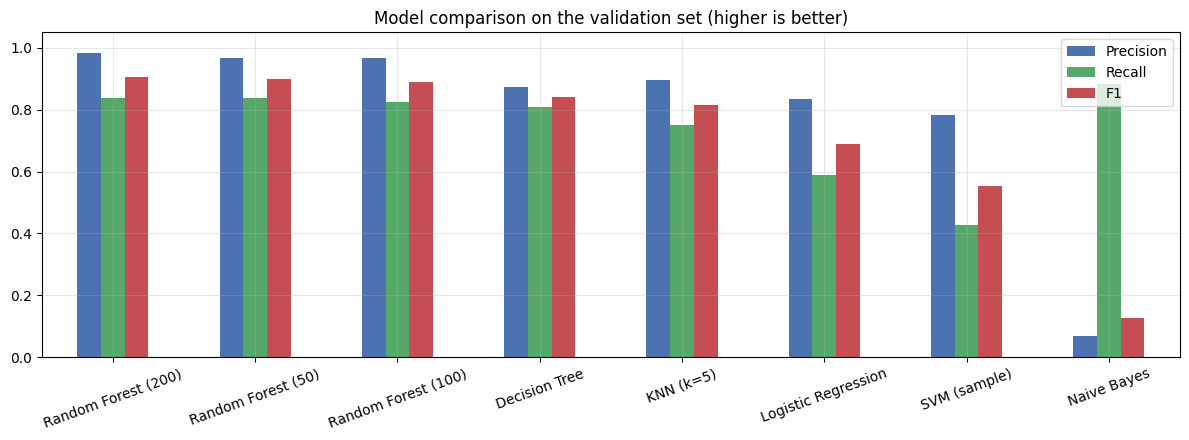

In [14]:
always_legit = np.zeros(len(y_val), dtype=int)
print(f"'Always legit' model -> accuracy = {accuracy_score(y_val, always_legit):.4%}, "
      f"recall = {recall_score(y_val, always_legit):.0%}, frauds caught = 0 of {int(y_val.sum())}")

# Compare models visually
ax = comparison[["Precision", "Recall", "F1"]].plot(kind="bar", figsize=(12, 4.5), rot=20,
                                                     color=["#4C72B0", "#55A868", "#C44E52"])
ax.set_title("Model comparison on the validation set (higher is better)")
ax.set_ylim(0, 1.05)
plt.tight_layout()
plt.show()

Deployed model: Random Forest (200)
{'Precision': 0.9828, 'Recall': 0.8382, 'F1': 0.9048, 'FPR': np.float64(0.0)}


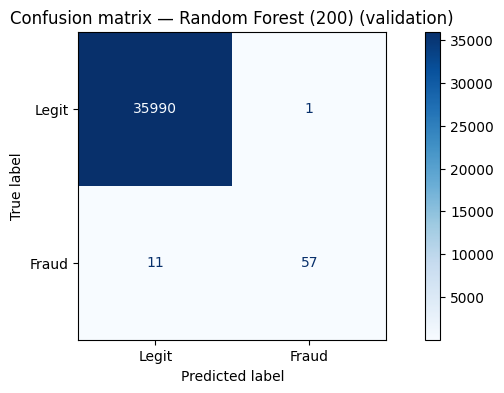

Saved and reloaded: deployed_fraud_model.joblib


In [15]:
# Pick the model with the best F1 as our "deployed" model
best_name = comparison["F1"].idxmax()
deployed_model = trained[best_name]
baseline = results[best_name]            # validation metrics = our "healthy" reference
print("Deployed model:", best_name)
print({k: round(v, 4) for k, v in baseline.items() if k in ["Precision", "Recall", "F1", "FPR"]})

# Confusion matrix of the deployed model
ConfusionMatrixDisplay.from_predictions(y_val, deployed_model.predict(X_val),
                                        display_labels=["Legit", "Fraud"], cmap="Blues")
plt.title(f"Confusion matrix — {best_name} (validation)")
plt.grid(False)
plt.show()

# Save the model to a file, just like a real deployment
joblib.dump(deployed_model, "deployed_fraud_model.joblib")
deployed_model = joblib.load("deployed_fraud_model.joblib")   # load it back to prove it works
print("Saved and reloaded: deployed_fraud_model.joblib")

**Model selection:** The model with the highest validation F1-score is selected as the deployed demonstration model. The confusion matrix shows the types of correct and incorrect predictions. The saved model is reloaded to verify that it can be used again.

## Phase 4 — Simulate live monitoring

In [16]:
WINDOW_HOURS = 4
live = live_df.copy()
live["Window"] = (((live["Time"] - SPLIT_TIME) // (WINDOW_HOURS * 3600)).astype(int) + 1).clip(upper=6)
live["Injected"] = "none"
rng = np.random.default_rng(RANDOM_STATE)

# ---------------- SIMULATED DATA DRIFT (Window 4) ----------------
w4 = live["Window"] == 4
live.loc[w4, "Amount"] = live.loc[w4, "Amount"] * 1.5
for col in ["V1", "V2", "V3", "V4"]:
    live.loc[w4, col] = live.loc[w4, col] + 0.5 * train_df[col].std()
live.loc[w4, "Injected"] = "data_drift"

# ---------------- SIMULATED CONCEPT DRIFT (Windows 5 and 6) ----------------
# A "new fraud pattern": legit-looking transactions with unusually HIGH V14 become fraud.
# The input data stays the same, only the meaning of the label changes.
v14_cut = train_df.loc[train_df["Class"] == 0, "V14"].quantile(0.997)
new_fraud = live["Window"].isin([5, 6]) & (live["Class"] == 0) & (live["V14"] > v14_cut)
live.loc[new_fraud, "Class"] = 1
live.loc[new_fraud, "Injected"] = "concept_drift"

# ---------------- SIMULATED FALSE-POSITIVE SPIKE (Window 6) ----------------
# 150 GENUINE high-amount purchases whose features look like fraud (copied from
# training frauds with small random noise), but their true label is 0 (legit).
n_extra = 150
extra = train_df[train_df["Class"] == 1].sample(n_extra, replace=True, random_state=RANDOM_STATE).copy()
extra[V_COLS] = extra[V_COLS] + rng.normal(0, 0.3, size=(n_extra, len(V_COLS)))
extra["Amount"] = rng.uniform(600, 2500, n_extra).round(2)
extra["Time"] = rng.uniform(SPLIT_TIME + 20 * 3600, SPLIT_TIME + 24 * 3600 - 1, n_extra).round()
extra["Class"] = 0
extra["Window"] = 6
extra["Injected"] = "fp_spike"
live = pd.concat([live, extra[live.columns]], ignore_index=True).sort_values("Time").reset_index(drop=True)

# Recompute Hour / Period / Amount_band / scaled columns because Amount and Time changed
live = add_slice_features(live)
live = add_scaled_features(live)

print("SIMULATED changes per window (rows affected):")
pd.crosstab(live["Window"], live["Injected"])

SIMULATED changes per window (rows affected):


Injected,concept_drift,data_drift,fp_spike,none
Window,,,,
1,0,0,0,9115
2,0,0,0,8558
3,0,0,0,29619
4,0,32508,0,0
5,71,0,0,32843
6,74,0,150,26702


In [17]:
# Run the deployed model on every live transaction
live["Pred"] = deployed_model.predict(live[FEATURES])

rows = []
for w in range(1, 7):
    part = live[live["Window"] == w]
    m = get_metrics(part["Class"], part["Pred"])
    m.update({"Window": w, "Hours": f"{24 + (w - 1) * 4}-{24 + w * 4}", "Rows": len(part), "Frauds": int(part["Class"].sum())})
    rows.append(m)

monitor = pd.DataFrame(rows).set_index("Window")
monitor[["Hours", "Rows", "Frauds", "Precision", "Recall", "F1", "FPR", "Alert_rate", "TP", "FP", "FN"]].round(4)

,Hours,Rows,Frauds,Precision,Recall,F1,FPR,Alert_rate,TP,FP,FN
Window,,,,,,,,,,,
1,24-28,9115,43,0.8500,0.7907,0.8193,0.0007,0.0044,34,6,9
2,28-32,8558,23,0.7143,0.8696,0.7843,0.0009,0.0033,20,8,3
3,32-36,29619,21,0.5926,0.7619,0.6667,0.0004,0.0009,16,11,5
4,36-40,32508,38,0.8276,0.6316,0.7164,0.0002,0.0009,24,5,14
5,40-44,32914,125,0.9070,0.3120,0.4643,0.0001,0.0013,39,4,86
6,44-48,26926,96,0.1034,0.1562,0.1245,0.0048,0.0054,15,130,81


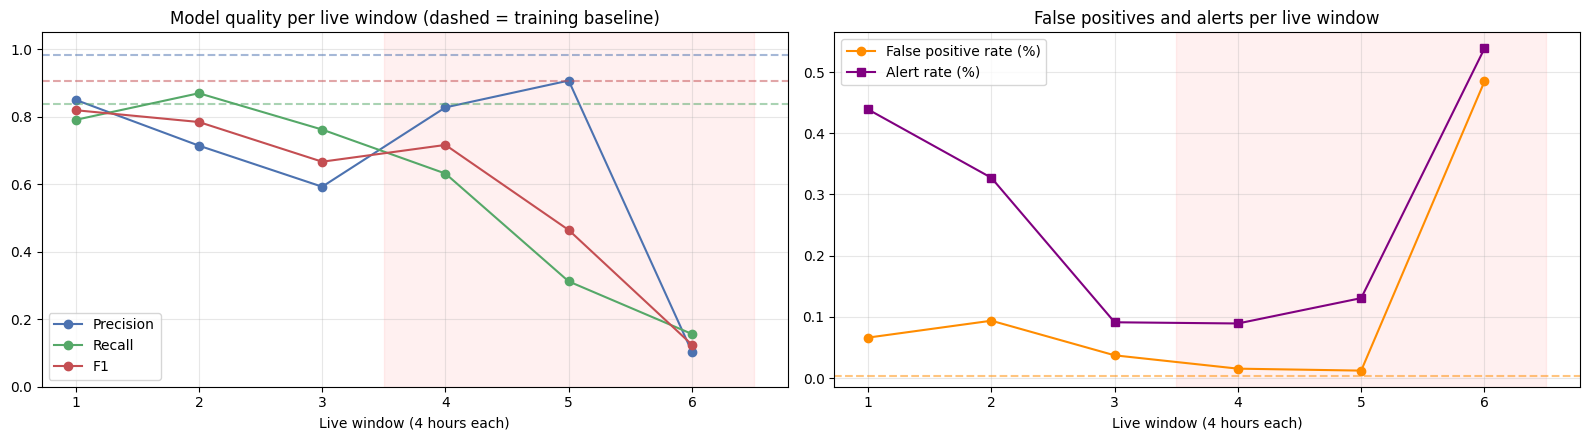

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
windows = monitor.index

for metric, color in [("Precision", "#4C72B0"), ("Recall", "#55A868"), ("F1", "#C44E52")]:
    axes[0].plot(windows, monitor[metric], marker="o", label=metric, color=color)
    axes[0].axhline(baseline[metric], linestyle="--", color=color, alpha=0.5)
axes[0].set_title("Model quality per live window (dashed = training baseline)")
axes[0].set_ylim(0, 1.05)

axes[1].plot(windows, monitor["FPR"] * 100, marker="o", label="False positive rate (%)", color="darkorange")
axes[1].plot(windows, monitor["Alert_rate"] * 100, marker="s", label="Alert rate (%)", color="purple")
axes[1].axhline(baseline["FPR"] * 100, linestyle="--", color="darkorange", alpha=0.5)
axes[1].set_title("False positives and alerts per live window")

for ax in axes:
    ax.axvspan(3.5, 6.5, color="red", alpha=0.06)          # shaded = windows with SIMULATED drift
    ax.set_xlabel("Live window (4 hours each)")
    ax.set_xticks(list(windows))
    ax.legend()
plt.tight_layout()
plt.show()

**Monitoring interpretation:** The second day is divided into six four-hour windows. Compare precision, recall and F1 across windows. Windows with injected changes are labelled in the simulation; do not interpret them as real-world production events.

## Phase 5 — Data drift detection (Exp 1, 8, 9)

In [19]:
def psi(expected, actual, bins=10):
    """Population Stability Index between reference values (expected) and new values (actual)."""
    expected, actual = np.asarray(expected), np.asarray(actual)
    edges = np.unique(np.quantile(expected, np.linspace(0, 1, bins + 1)))   # bin edges from reference data
    edges[0], edges[-1] = -np.inf, np.inf
    expected_pct = np.histogram(expected, edges)[0] / len(expected)
    actual_pct = np.histogram(actual, edges)[0] / len(actual)
    expected_pct = np.clip(expected_pct, 1e-6, None)                        # avoid log(0)
    actual_pct = np.clip(actual_pct, 1e-6, None)
    return float(np.sum((actual_pct - expected_pct) * np.log(actual_pct / expected_pct)))


DRIFT_COLS = ["Amount", "V1", "V2", "V3", "V4"]
drift_rows = []
for w in range(1, 7):
    part = live[live["Window"] == w]
    for col in DRIFT_COLS:
        ks_stat, p_value = ks_2samp(train_df[col], part[col])
        drift_rows.append({"Window": w, "Feature": col, "KS_stat": ks_stat,
                           "KS_pvalue": p_value, "PSI": psi(train_df[col], part[col])})
drift = pd.DataFrame(drift_rows)

psi_table = drift.pivot(index="Feature", columns="Window", values="PSI").loc[DRIFT_COLS]
ks_table = drift.pivot(index="Feature", columns="Window", values="KS_stat").loc[DRIFT_COLS]
print("KS statistic vs training (0 = same, 1 = totally different):")
display(ks_table.round(3))
print("PSI vs training:")
display(psi_table.round(3))

KS statistic vs training (0 = same, 1 = totally different):


Window,1,2,3,4,5,6
Feature,,,,,,
Amount,0.125,0.165,0.061,0.121,0.026,0.078
V1,0.386,0.449,0.435,0.457,0.431,0.407
V2,0.104,0.082,0.098,0.285,0.055,0.071
V3,0.452,0.442,0.518,0.350,0.532,0.536
V4,0.108,0.158,0.167,0.095,0.185,0.197


PSI vs training:


Window,1,2,3,4,5,6
Feature,,,,,,
Amount,0.084,0.155,0.017,0.164,0.004,0.028
V1,1.586,1.732,1.562,1.655,1.579,1.578
V2,0.090,0.105,0.054,0.461,0.030,0.043
V3,1.097,1.105,1.425,0.680,1.500,1.521
V4,0.154,0.204,0.189,0.097,0.222,0.253


### A real finding: V1 and V3 drift on day 2

,Day 1 (training) mean,Day 2 (windows 1-3) mean
Amount,90.560,86.255
V1,-0.247,0.298
V2,0.021,-0.046
V3,0.673,-0.588
V4,0.135,-0.078


Importance rank (out of 29) of the monitored features: {'Amount': 24, 'V1': 14, 'V2': 25, 'V3': 18, 'V4': 9}


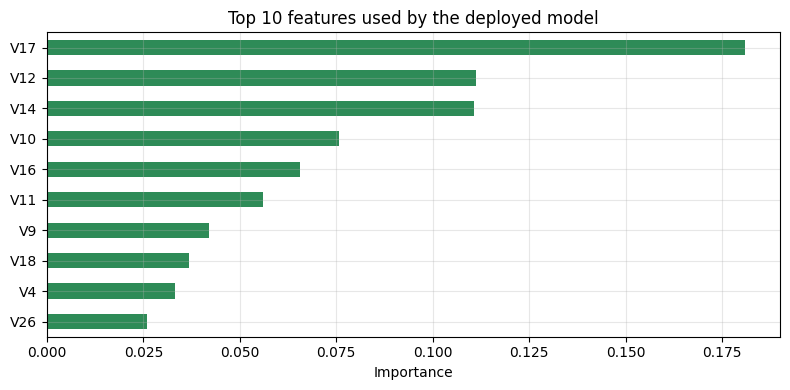

In [20]:
day_means = pd.DataFrame({
    "Day 1 (training) mean": train_df[DRIFT_COLS].mean(),
    "Day 2 (windows 1-3) mean": live.loc[live["Window"] <= 3, DRIFT_COLS].mean(),
})
display(day_means.round(3))

# Which features does the deployed model actually use? (Random Forest feature importance)
if hasattr(deployed_model, "feature_importances_"):
    importance = pd.Series(deployed_model.feature_importances_, index=FEATURES).sort_values(ascending=False)
    rank = importance.rank(ascending=False).astype(int)
    print("Importance rank (out of 29) of the monitored features:",
          {col: int(rank[col if col != "Amount" else "Amount_scaled"]) for col in DRIFT_COLS})
    importance.head(10)[::-1].plot(kind="barh", figsize=(8, 4), color="seagreen")
    plt.title("Top 10 features used by the deployed model")
    plt.xlabel("Importance")
    plt.tight_layout()
    plt.show()

### Reference period

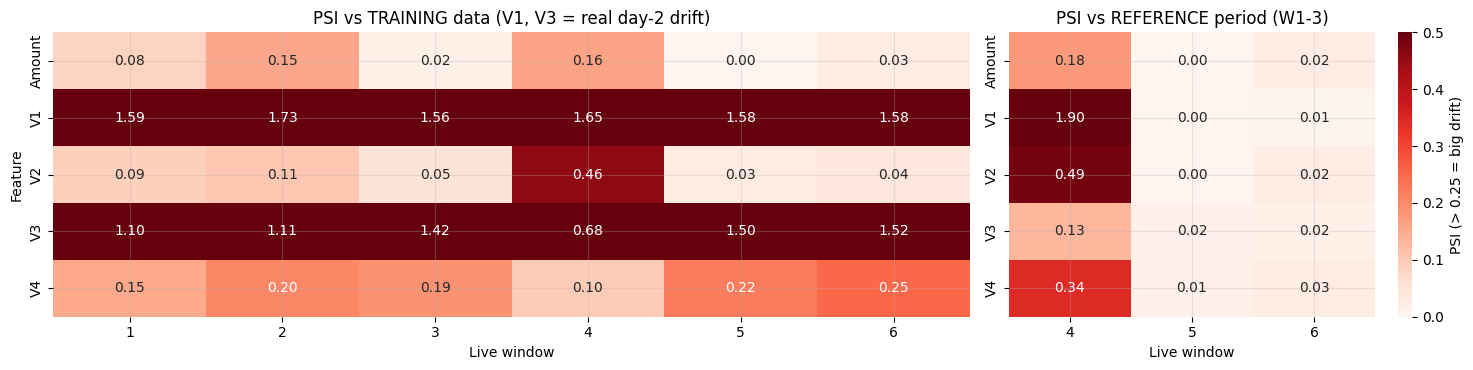

,Compared with,Max PSI,Drifted features,Data drift?
Window,,,,
1,training,1.586,"V1, V3",YES
2,training,1.732,"V1, V3",YES
3,training,1.562,"V1, V3",YES
4,reference W1-3,1.902,"V1, V2, V4",YES
5,reference W1-3,0.015,-,no
6,reference W1-3,0.028,-,no


In [21]:
PSI_LIMIT = 0.25
reference = live[live["Window"] <= 3]

psi_vs_ref = pd.DataFrame({w: {col: psi(reference[col], live.loc[live["Window"] == w, col]) for col in DRIFT_COLS}
                           for w in [4, 5, 6]}).loc[DRIFT_COLS]

drift_features, window_drift_score = {}, {}
for w in range(1, 7):
    scores = psi_table[w] if w <= 3 else psi_vs_ref[w]
    drift_features[w] = [col for col in DRIFT_COLS if scores[col] > PSI_LIMIT]
    window_drift_score[w] = scores.max()
window_drift_score = pd.Series(window_drift_score)
data_drift_flag = pd.Series({w: len(drift_features[w]) > 0 for w in range(1, 7)})

fig, axes = plt.subplots(1, 2, figsize=(15, 3.8), gridspec_kw={"width_ratios": [2, 1]})
sns.heatmap(psi_table, annot=True, fmt=".2f", cmap="Reds", vmin=0, vmax=0.5, ax=axes[0], cbar=False)
axes[0].set_title("PSI vs TRAINING data (V1, V3 = real day-2 drift)")
axes[0].set_xlabel("Live window")
sns.heatmap(psi_vs_ref, annot=True, fmt=".2f", cmap="Reds", vmin=0, vmax=0.5, ax=axes[1],
            cbar_kws={"label": "PSI (> 0.25 = big drift)"})
axes[1].set_title("PSI vs REFERENCE period (W1-3)")
axes[1].set_xlabel("Live window")
plt.tight_layout()
plt.show()

pd.DataFrame({"Compared with": ["training"] * 3 + ["reference W1-3"] * 3,
              "Max PSI": window_drift_score.round(3),
              "Drifted features": [", ".join(drift_features[w]) or "-" for w in range(1, 7)],
              "Data drift?": data_drift_flag.map({True: "YES", False: "no"})}).rename_axis("Window")

Variance explained by the 2 components: [0.122 0.104]


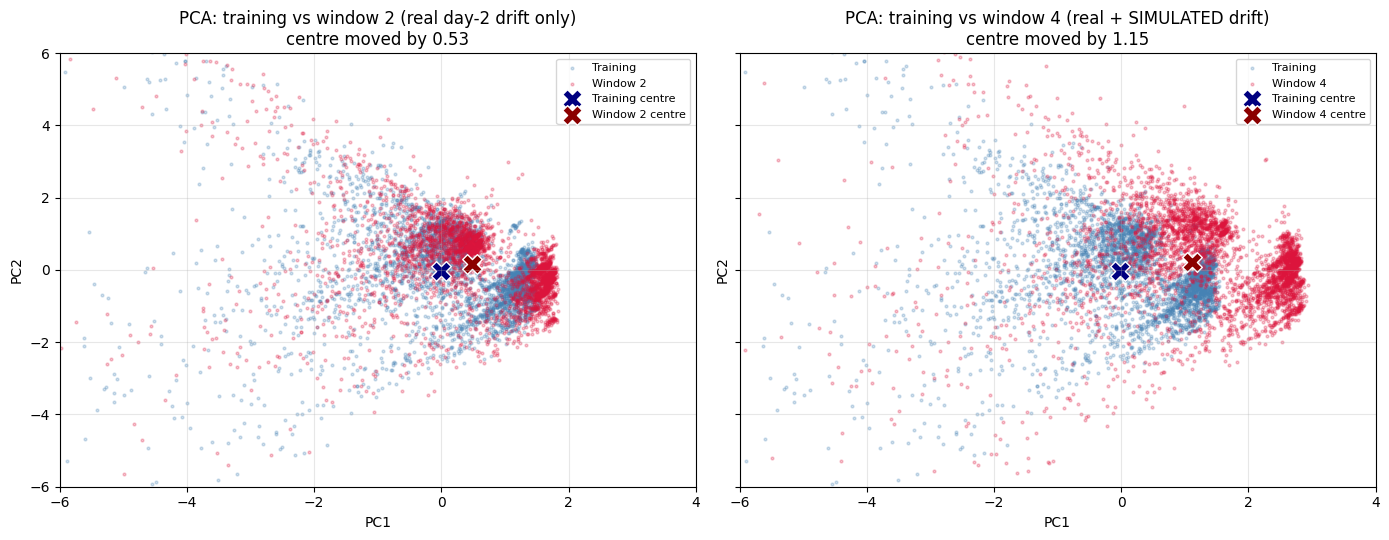

In [22]:
# PCA: squeeze all 29 features into 2 numbers per transaction so we can plot them
pca = PCA(n_components=2, random_state=RANDOM_STATE).fit(train_df[FEATURES])
print("Variance explained by the 2 components:", pca.explained_variance_ratio_.round(3))

train_2d = pca.transform(train_df[FEATURES].sample(4000, random_state=RANDOM_STATE))
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), sharex=True, sharey=True)
for ax, w, title in [(axes[0], 2, "real day-2 drift only"), (axes[1], 4, "real + SIMULATED drift")]:
    window_rows = live.loc[live["Window"] == w, FEATURES]
    win_2d = pca.transform(window_rows.sample(min(4000, len(window_rows)), random_state=RANDOM_STATE))
    ax.scatter(train_2d[:, 0], train_2d[:, 1], s=4, alpha=0.25, label="Training", color="steelblue")
    ax.scatter(win_2d[:, 0], win_2d[:, 1], s=4, alpha=0.25, label=f"Window {w}", color="crimson")
    ax.scatter(*train_2d.mean(axis=0), marker="X", s=200, color="navy", edgecolor="white", label="Training centre")
    ax.scatter(*win_2d.mean(axis=0), marker="X", s=200, color="darkred", edgecolor="white", label=f"Window {w} centre")
    shift = np.linalg.norm(win_2d.mean(axis=0) - train_2d.mean(axis=0))
    ax.set_title(f"PCA: training vs window {w} ({title})\ncentre moved by {shift:.2f}")
    ax.set_xlabel("PC1"); ax.set_ylabel("PC2")
    ax.set_xlim(-6, 4); ax.set_ylim(-6, 6)
    ax.legend(fontsize=8, loc="upper right")
plt.tight_layout()
plt.show()

,Training,W1,W2,W3,W4,W5,W6
Cluster 0,47.1,41.9,48.4,48.9,50.0,47.8,44.8
Cluster 1,1.7,2.2,1.4,1.1,1.4,1.6,2.4
Cluster 2,48.6,54.4,48.7,47.0,46.1,48.2,51.0
Cluster 3,2.5,1.4,1.5,3.0,2.5,2.4,1.8


Cluster shift per window: {'W1': 0.063, 'W2': 0.013, 'W3': 0.023, 'W4': 0.028, 'W5': 0.007, 'W6': 0.031}


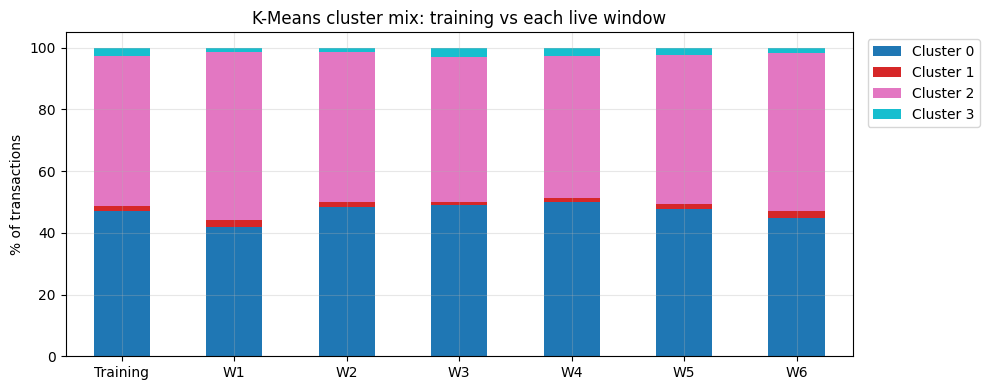

In [23]:
# K-Means: group training transactions into 4 clusters, then check each window's cluster mix
kmeans = KMeans(n_clusters=4, n_init=10, random_state=RANDOM_STATE).fit(train_df[FEATURES])
train_df["Cluster"] = kmeans.labels_
val_df["Cluster"] = kmeans.predict(val_df[FEATURES])
live["Cluster"] = kmeans.predict(live[FEATURES])

cluster_mix = pd.DataFrame({"Training": train_df["Cluster"].value_counts(normalize=True)})
for w in range(1, 7):
    cluster_mix[f"W{w}"] = live.loc[live["Window"] == w, "Cluster"].value_counts(normalize=True)
cluster_mix = cluster_mix.fillna(0).sort_index()
cluster_mix.index = [f"Cluster {c}" for c in cluster_mix.index]

# Cluster shift = half the sum of absolute differences (0 = same mix, 1 = completely different)
cluster_shift = (cluster_mix.sub(cluster_mix["Training"], axis=0).abs().sum() / 2).drop("Training")
display((cluster_mix * 100).round(1))
print("Cluster shift per window:", cluster_shift.round(3).to_dict())

(cluster_mix.T * 100).plot(kind="bar", stacked=True, figsize=(10, 4), rot=0, colormap="tab10")
plt.ylabel("% of transactions")
plt.title("K-Means cluster mix: training vs each live window")
plt.legend(bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout()
plt.show()

**Drift interpretation:** KS and PSI compare feature distributions. The early day-two differences in V1/V3 are present in the source data, while additional changes are injected later for demonstration. A drift signal alone does not prove that model quality has fallen.

## Phase 6 — Concept drift detection

In [24]:
RECALL_DROP_LIMIT = 0.15
F1_DROP_LIMIT = 0.30

concept = pd.DataFrame(index=pd.Index(range(1, 7), name="Window"))
concept["Recall"] = monitor["Recall"]
concept["F1"] = monitor["F1"]
concept["Recall_drop_%"] = (baseline["Recall"] - monitor["Recall"]) / baseline["Recall"] * 100
concept["F1_drop_%"] = (baseline["F1"] - monitor["F1"]) / baseline["F1"] * 100
concept["Perf_drop"] = ((concept["Recall_drop_%"] > RECALL_DROP_LIMIT * 100) |
                        (concept["F1_drop_%"] > F1_DROP_LIMIT * 100))
concept["Max_PSI"] = window_drift_score
concept["Data_drift"] = data_drift_flag


def diagnose(row):
    if row["Data_drift"] and row["Perf_drop"]:
        return "Data drift + performance drop"
    if row["Data_drift"]:
        return "Data drift (model still OK)"
    if row["Perf_drop"]:
        return "CONCEPT DRIFT"
    return "Healthy"


concept["Diagnosis"] = concept.apply(diagnose, axis=1)
concept.round(3)

,Recall,F1,Recall_drop_%,F1_drop_%,Perf_drop,Max_PSI,Data_drift,Diagnosis
Window,,,,,,,,
1,0.791,0.819,5.671,9.448,False,1.586,True,Data drift (model still OK)
2,0.870,0.784,-3.738,13.313,False,1.732,True,Data drift (model still OK)
3,0.762,0.667,9.106,26.316,False,1.562,True,Data drift (model still OK)
4,0.632,0.716,24.654,20.817,True,1.902,True,Data drift + performance drop
5,0.312,0.464,62.779,48.684,True,0.015,False,CONCEPT DRIFT
6,0.156,0.124,81.360,86.242,True,0.028,False,CONCEPT DRIFT


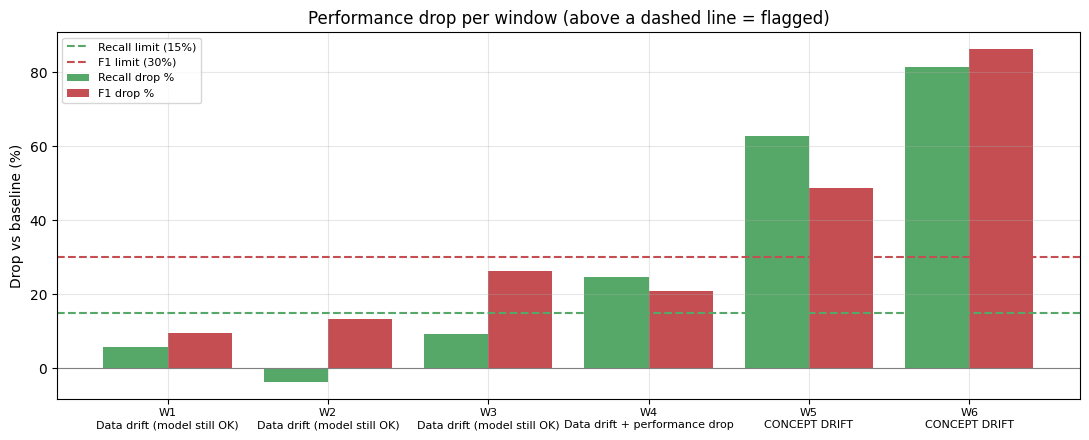

In [25]:
fig, ax = plt.subplots(figsize=(11, 4.5))
x = np.arange(1, 7)
ax.bar(x - 0.2, concept["Recall_drop_%"], width=0.4, label="Recall drop %", color="#55A868")
ax.bar(x + 0.2, concept["F1_drop_%"], width=0.4, label="F1 drop %", color="#C44E52")
ax.axhline(RECALL_DROP_LIMIT * 100, color="#55A868", linestyle="--", label="Recall limit (15%)")
ax.axhline(F1_DROP_LIMIT * 100, color="#C44E52", linestyle="--", label="F1 limit (30%)")
ax.axhline(0, color="gray", linewidth=0.8)
ax.set_xticks(x)
ax.set_xticklabels([f"W{w}\n{d}" for w, d in zip(x, concept["Diagnosis"])], fontsize=8)
ax.set_ylabel("Drop vs baseline (%)")
ax.set_title("Performance drop per window (above a dashed line = flagged)")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

**Concept-drift interpretation:** This notebook uses performance degradation as a warning signal for possible concept drift. Because the later labels are deliberately changed in the simulation, the detected concept drift is a controlled demonstration rather than a confirmed real-world event.

## Phase 7 — Slice-level false-positive spikes

In [26]:
val_df["Pred"] = deployed_model.predict(val_df[FEATURES])

SLICES = ([("Amount_band", b) for b in ["Low", "Medium", "High"]] +
          [("Period", p) for p in ["Day", "Night"]] +
          [("Cluster", c) for c in range(4)])
MIN_BASELINE_FPR = 0.0025   # 0.25%
MIN_FALSE_ALARMS = 10


def slice_fpr(data, col, value):
    legit = data[(data[col] == value) & (data["Class"] == 0)]
    false_alarms = int(legit["Pred"].sum())
    return (false_alarms / len(legit) if len(legit) else 0.0), false_alarms


slice_rows = []
for col, value in SLICES:
    name = f"{col}_{value}"
    base_fpr, _ = slice_fpr(val_df, col, value)
    for w in range(1, 7):
        fpr, n_fp = slice_fpr(live[live["Window"] == w], col, value)
        limit = 2 * max(base_fpr, MIN_BASELINE_FPR)
        slice_rows.append({"Slice": name, "Window": w, "Baseline_FPR_%": base_fpr * 100, "FPR_%": fpr * 100,
                           "False_alarms": n_fp, "Spike": (fpr > limit) and (n_fp >= MIN_FALSE_ALARMS)})
slices = pd.DataFrame(slice_rows)

fpr_heat = slices.pivot(index="Slice", columns="Window", values="FPR_%")
fpr_heat = fpr_heat.loc[[f"{c}_{v}" for c, v in SLICES]]
flagged = slices[slices["Spike"]]
print("Flagged slices:")
flagged.round(3)

Flagged slices:


,Slice,Window,Baseline_FPR_%,FPR_%,False_alarms,Spike
17,Amount_band_High,6,0.014,2.788,122,True
41,Cluster_1,6,0.180,13.462,77,True
53,Cluster_3,6,0.000,2.505,12,True


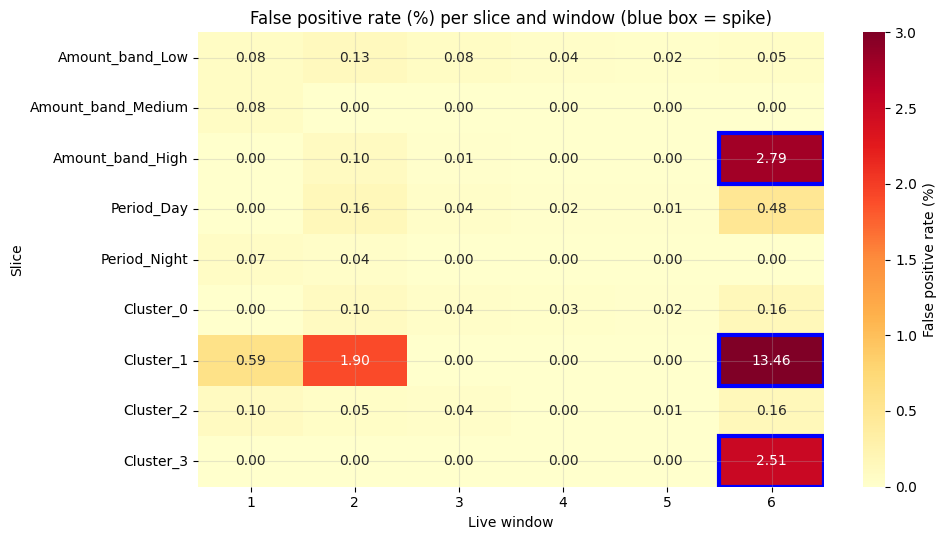

In [27]:
plt.figure(figsize=(10, 5.5))
sns.heatmap(fpr_heat, annot=True, fmt=".2f", cmap="YlOrRd", vmax=3,
            cbar_kws={"label": "False positive rate (%)"})
for _, r in flagged.iterrows():                      # blue box around every flagged cell
    row_pos = list(fpr_heat.index).index(r["Slice"])
    plt.gca().add_patch(plt.Rectangle((r["Window"] - 1, row_pos), 1, 1, fill=False, edgecolor="blue", lw=3))
plt.title("False positive rate (%) per slice and window (blue box = spike)")
plt.xlabel("Live window")
plt.ylabel("Slice")
plt.tight_layout()
plt.show()

**Slice-monitoring interpretation:** The table and heatmap identify groups where legitimate transactions are incorrectly flagged more often. Check both the false-positive rate and the number of false alarms; a rate based on very few records can be unstable.

## Phase 8 — Alerts and retraining

In [28]:
alert_rows = []
for w in range(1, 7):
    spikes = flagged.loc[flagged["Window"] == w, "Slice"].tolist()
    alert_rows.append({
        "Window": w,
        "Data drift": f"YES ({', '.join(drift_features[w])})" if data_drift_flag[w] else "no",
        "Max PSI": round(window_drift_score[w], 3),
        "Recall/F1 drop": "YES" if concept.loc[w, "Perf_drop"] else "no",
        "F1": round(concept.loc[w, "F1"], 3),
        "FP spike": ", ".join(spikes) if spikes else "-",
        "Diagnosis": concept.loc[w, "Diagnosis"],
    })
alerts = pd.DataFrame(alert_rows).set_index("Window")
display(alerts)

print("\nALERT LOG")
for w, r in alerts.iterrows():
    print(f"Window {w} | Data drift: {r['Data drift']:<16} | F1 drop: {r['Recall/F1 drop']:<3} | "
          f"FP spike: {r['FP spike']:<40} | {r['Diagnosis']}")

,Data drift,Max PSI,Recall/F1 drop,F1,FP spike,Diagnosis
Window,,,,,,
1,"YES (V1, V3)",1.586,no,0.819,-,Data drift (model still OK)
2,"YES (V1, V3)",1.732,no,0.784,-,Data drift (model still OK)
3,"YES (V1, V3)",1.562,no,0.667,-,Data drift (model still OK)
4,"YES (V1, V2, V4)",1.902,YES,0.716,-,Data drift + performance drop
5,no,0.015,YES,0.464,-,CONCEPT DRIFT
6,no,0.028,YES,0.124,"Amount_band_High, Cluster_1, Cluster_3",CONCEPT DRIFT



ALERT LOG
Window 1 | Data drift: YES (V1, V3)     | F1 drop: no  | FP spike: -                                        | Data drift (model still OK)
Window 2 | Data drift: YES (V1, V3)     | F1 drop: no  | FP spike: -                                        | Data drift (model still OK)
Window 3 | Data drift: YES (V1, V3)     | F1 drop: no  | FP spike: -                                        | Data drift (model still OK)
Window 4 | Data drift: YES (V1, V2, V4) | F1 drop: YES | FP spike: -                                        | Data drift + performance drop
Window 5 | Data drift: no               | F1 drop: YES | FP spike: -                                        | CONCEPT DRIFT
Window 6 | Data drift: no               | F1 drop: YES | FP spike: Amount_band_High, Cluster_1, Cluster_3   | CONCEPT DRIFT


In [29]:
n_trees = getattr(deployed_model, "n_estimators", 100)
window5 = live[live["Window"] == 5]
retrain_data = pd.concat([fit_df, window5], ignore_index=True)

# (a) Simple retrain: old data + window 5, every row counts the same
start = time.time()
retrained_plain = RandomForestClassifier(n_estimators=n_trees, n_jobs=-1, random_state=RANDOM_STATE)
retrained_plain.fit(retrain_data[FEATURES], retrain_data["Class"])

# (b) Retrain where recent rows count 10x. After concept drift the old data still says
#     "high V14 = legit", so we tell the model to trust the newest data more.
weights = np.r_[np.ones(len(fit_df)), np.full(len(window5), 10.0)]
retrained_model = RandomForestClassifier(n_estimators=n_trees, n_jobs=-1, random_state=RANDOM_STATE)
retrained_model.fit(retrain_data[FEATURES], retrain_data["Class"], sample_weight=weights)
print(f"Two Random Forests ({n_trees} trees) retrained on {len(retrain_data):,} rows in {time.time() - start:.1f}s")

window6 = live[live["Window"] == 6]
new_pattern_rows = window6["Injected"] == "concept_drift"
compare = {}
for name, model in [("Before: deployed", deployed_model),
                    ("After: retrained (plain)", retrained_plain),
                    ("After: retrained (recent x10)", retrained_model)]:
    pred_w6 = model.predict(window6[FEATURES])
    m = get_metrics(window6["Class"], pred_w6)
    compare[name] = {"W6 Precision": m["Precision"], "W6 Recall": m["Recall"], "W6 F1": m["F1"],
                     "New-pattern frauds caught": f"{int(pred_w6[new_pattern_rows.values].sum())} / {int(new_pattern_rows.sum())}",
                     "Validation F1": f1_score(y_val, model.predict(X_val))}
before_after = pd.DataFrame(compare).T
before_after

Two Random Forests (200 trees) retrained on 141,091 rows in 430.5s


,W6 Precision,W6 Recall,W6 F1,New-pattern frauds caught,Validation F1
Before: deployed,0.103448,0.15625,0.124481,0 / 74,0.904762
After: retrained (plain),0.260606,0.447917,0.329502,29 / 74,0.878049
After: retrained (recent x10),0.256098,0.4375,0.323077,28 / 74,0.861789


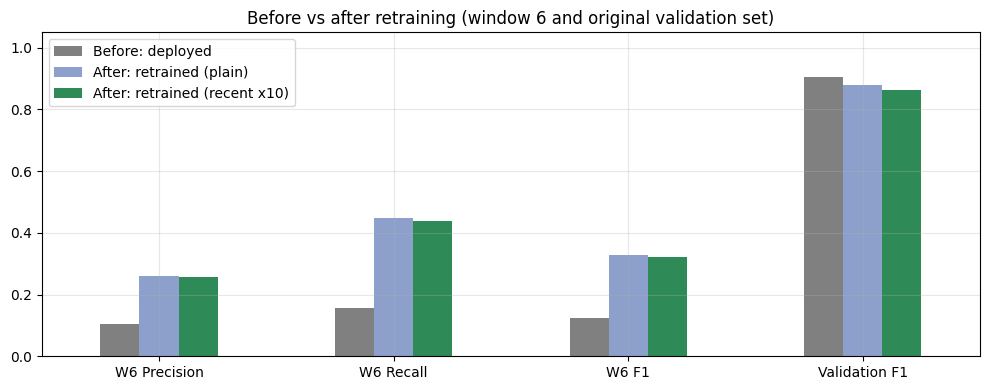

In [30]:
ax = before_after[["W6 Precision", "W6 Recall", "W6 F1", "Validation F1"]].astype(float).T.plot(
    kind="bar", figsize=(10, 4), rot=0, color=["gray", "#8DA0CB", "seagreen"])
ax.set_ylim(0, 1.05)
ax.set_title("Before vs after retraining (window 6 and original validation set)")
plt.tight_layout()
plt.show()

### Optional — small neural network (Exp 10)

In [31]:
nn_rows = []
normal_windows = live[live["Window"] <= 3]
drifted_windows = live[live["Window"] >= 4]
for activation in ["logistic", "tanh", "relu"]:
    start = time.time()
    mlp = MLPClassifier(hidden_layer_sizes=(32,), activation=activation, max_iter=50, random_state=RANDOM_STATE)
    mlp.fit(X_fit, y_fit)
    nn_rows.append({
        "Activation": {"logistic": "Sigmoid", "tanh": "Tanh", "relu": "ReLU"}[activation],
        "Validation F1": f1_score(y_val, mlp.predict(X_val)),
        "Live W1-3 F1": f1_score(normal_windows["Class"], mlp.predict(normal_windows[FEATURES])),
        "Live W4-6 F1": f1_score(drifted_windows["Class"], mlp.predict(drifted_windows[FEATURES])),
        "Train time (s)": round(time.time() - start, 1),
    })
nn_results = pd.DataFrame(nn_rows).set_index("Activation")
nn_results.round(3)

,Validation F1,Live W1-3 F1,Live W4-6 F1,Train time (s)
Activation,,,,
Sigmoid,0.818,0.826,0.356,4.1
Tanh,0.915,0.589,0.259,4.9
ReLU,0.908,0.594,0.308,6.7


**Retraining interpretation:** Compare the original model, plain retraining and recent-data-weighted retraining. The comparison is an experiment on simulated labels; it illustrates a possible response, not a guarantee that retraining will always improve a production model.

## Phase 9 — Conclusion

In [32]:
def windows_with(diagnosis):
    return [w for w in alerts.index if alerts.loc[w, "Diagnosis"] == diagnosis]

before, after = before_after.iloc[0], before_after.iloc[2]
print("=" * 72)
print("PROJECT ML_79 — SUMMARY OF FINDINGS")
print("=" * 72)
print(f"Data used            : {DATA_SOURCE}, {len(df):,} rows after cleaning")
print(f"Deployed model       : {best_name}")
print(f"Baseline (val)       : precision {baseline['Precision']:.3f}, recall {baseline['Recall']:.3f}, F1 {baseline['F1']:.3f}")
print(f"Harmless data drift  : windows {windows_with('Data drift (model still OK)')}")
print(f"Data drift + drop    : windows {windows_with('Data drift + performance drop')}")
print(f"Concept drift        : windows {windows_with('CONCEPT DRIFT')}")
print(f"Healthy              : windows {windows_with('Healthy')}")
print(f"FP spikes            : {[(int(r.Window), r.Slice) for r in flagged.itertuples()]}")
print(f"Retraining (W6)      : recall {before['W6 Recall']:.3f} -> {after['W6 Recall']:.3f}, "
      f"F1 {before['W6 F1']:.3f} -> {after['W6 F1']:.3f}, new-pattern caught {before['New-pattern frauds caught']} -> {after['New-pattern frauds caught']}")
print("=" * 72)

PROJECT ML_79 — SUMMARY OF FINDINGS
Data used            : real Kaggle data, 283,726 rows after cleaning
Deployed model       : Random Forest (200)
Baseline (val)       : precision 0.983, recall 0.838, F1 0.905
Harmless data drift  : windows [1, 2, 3]
Data drift + drop    : windows [4]
Concept drift        : windows [5, 6]
Healthy              : windows []
FP spikes            : [(6, 'Amount_band_High'), (6, 'Cluster_1'), (6, 'Cluster_3')]
Retraining (W6)      : recall 0.156 -> 0.438, F1 0.124 -> 0.323, new-pattern caught 0 / 74 -> 28 / 74


### Findings

### How to explain the result

## Phase 10 — Try a transaction prediction

In [33]:
# Choose a row from the simulated incoming transactions (0 means the first row)
DEMO_ROW_POSITION = 0

if len(live) == 0:
    print("No monitoring transactions are available. Run the notebook from the beginning.")
else:
    DEMO_ROW_POSITION = int(np.clip(DEMO_ROW_POSITION, 0, len(live) - 1))
    demo_transaction = live.iloc[[DEMO_ROW_POSITION]]
    demo_prediction = int(deployed_model.predict(demo_transaction[FEATURES])[0])
    actual_label = int(demo_transaction["Class"].iloc[0])
    predicted_label = "FRAUDULENT — review this transaction" if demo_prediction == 1 else "LEGITIMATE — no fraud alert"
    actual_text = "Fraudulent" if actual_label == 1 else "Legitimate"

    print("=" * 58)
    print("TRANSACTION PREDICTION DEMONSTRATION")
    print("=" * 58)
    print(f"Selected monitoring row : {DEMO_ROW_POSITION}")
    print(f"Transaction amount      : {demo_transaction['Amount'].iloc[0]:,.2f}")
    print(f"Transaction time        : {demo_transaction['Time'].iloc[0]:,.0f} seconds from dataset start")
    print(f"Model prediction        : {predicted_label}")
    print(f"Actual dataset label    : {actual_text} (shown only for evaluation)")
    print("Prediction correct      :", "YES" if demo_prediction == actual_label else "NO")
    print("=" * 58)


TRANSACTION PREDICTION DEMONSTRATION
Selected monitoring row : 0
Transaction amount      : 63.48
Transaction time        : 86,400 seconds from dataset start
Model prediction        : LEGITIMATE — no fraud alert
Actual dataset label    : Legitimate (shown only for evaluation)
Prediction correct      : YES


## Phase 11 — Final monitoring dashboard

,Transactions,Fraud cases,Precision,Recall,F1-score,Data drift,Performance drop,False-positive slices
Monitoring window,,,,,,,,
1,9115,43,0.850,0.791,0.819,FLAG,OK,None
2,8558,23,0.714,0.870,0.784,FLAG,OK,None
3,29619,21,0.593,0.762,0.667,FLAG,OK,None
4,32508,38,0.828,0.632,0.716,FLAG,FLAG,None
5,32914,125,0.907,0.312,0.464,OK,FLAG,None
6,26926,96,0.103,0.156,0.124,OK,FLAG,"Amount_band_High, Cluster_1, Cluster_3"


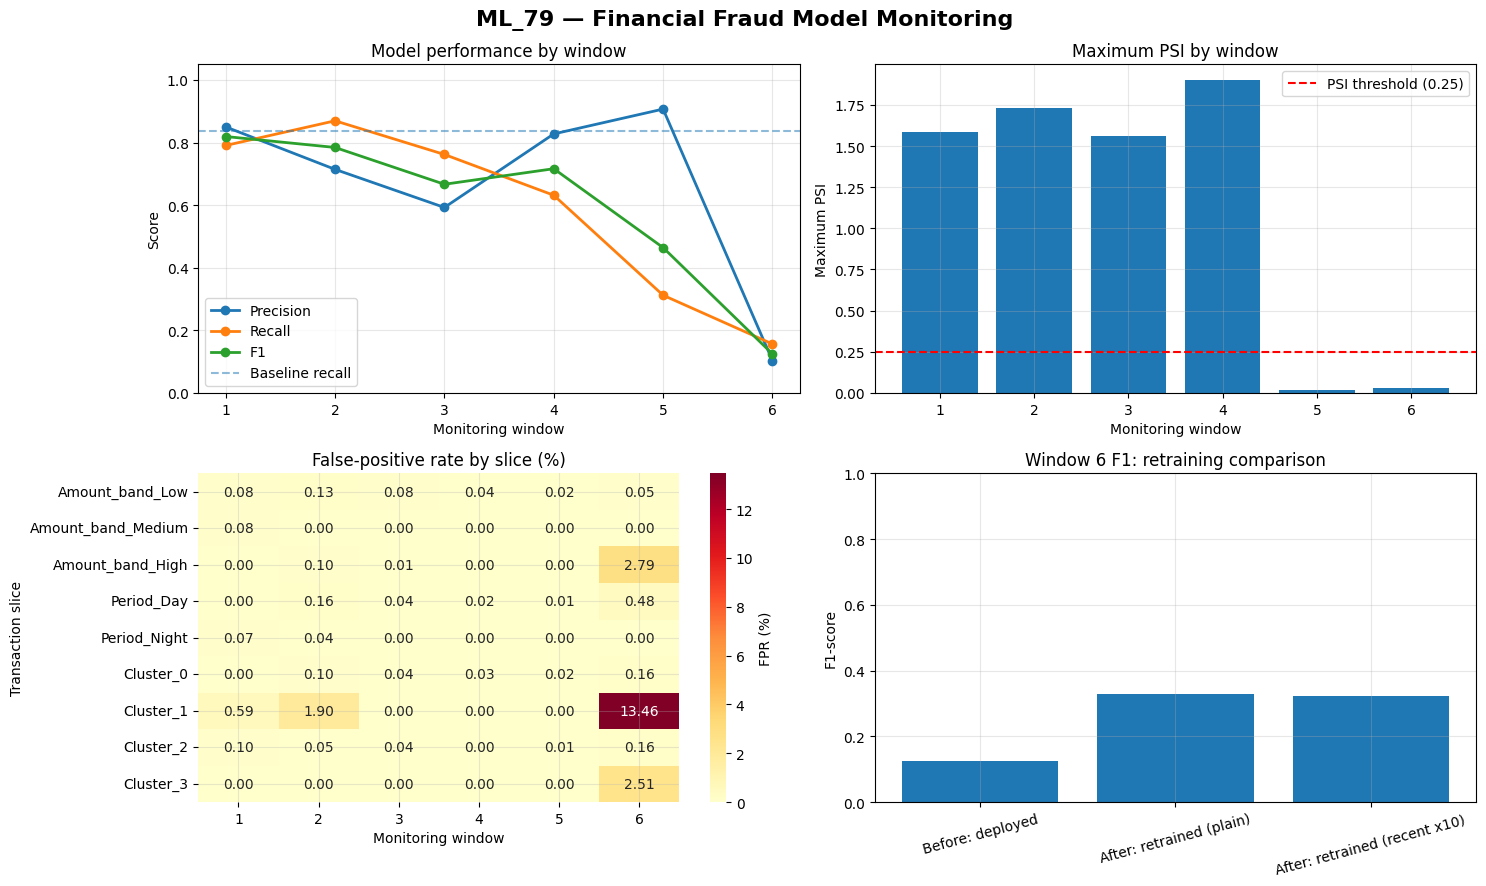


FINAL AUTOMATED INTERPRETATION
Data-drift windows: [1, 2, 3, 4]
Performance-drop windows: [4, 5, 6]
Windows with slice-level false-positive spikes: [6]
Selected model: Random Forest (200)
Baseline validation F1: 0.905
Reminder: later injected drift/label changes are simulated for demonstration.


In [34]:
# Consolidated monitoring view — generated from this notebook's calculated results
from IPython.display import display

# Summary table: one row per simulated monitoring window
final_dashboard = pd.DataFrame(index=monitor.index)
final_dashboard.index.name = "Monitoring window"
final_dashboard["Transactions"] = monitor["Rows"].astype(int)
final_dashboard["Fraud cases"] = monitor["Frauds"].astype(int)
final_dashboard["Precision"] = monitor["Precision"].round(3)
final_dashboard["Recall"] = monitor["Recall"].round(3)
final_dashboard["F1-score"] = monitor["F1"].round(3)
final_dashboard["Data drift"] = data_drift_flag.map({True: "FLAG", False: "OK"})
final_dashboard["Performance drop"] = concept["Perf_drop"].map({True: "FLAG", False: "OK"})
final_dashboard["False-positive slices"] = [
    ", ".join(flagged.loc[flagged["Window"] == w, "Slice"].tolist()) or "None"
    for w in final_dashboard.index
]
display(final_dashboard)

# Four compact visual summaries
fig, axes = plt.subplots(2, 2, figsize=(15, 9))

# 1. Performance through monitoring windows
for metric in ["Precision", "Recall", "F1"]:
    axes[0, 0].plot(monitor.index, monitor[metric], marker="o", linewidth=2, label=metric)
axes[0, 0].axhline(baseline["Recall"], linestyle="--", alpha=0.5, label="Baseline recall")
axes[0, 0].set_title("Model performance by window")
axes[0, 0].set_xlabel("Monitoring window"); axes[0, 0].set_ylabel("Score")
axes[0, 0].set_xticks(monitor.index); axes[0, 0].set_ylim(0, 1.05); axes[0, 0].legend()

# 2. PSI drift score per window
axes[0, 1].bar(window_drift_score.index, window_drift_score.values)
axes[0, 1].axhline(PSI_LIMIT, color="red", linestyle="--", label=f"PSI threshold ({PSI_LIMIT})")
axes[0, 1].set_title("Maximum PSI by window")
axes[0, 1].set_xlabel("Monitoring window"); axes[0, 1].set_ylabel("Maximum PSI")
axes[0, 1].set_xticks(window_drift_score.index); axes[0, 1].legend()

# 3. False-positive rate by slice and window
sns.heatmap(fpr_heat, cmap="YlOrRd", annot=True, fmt=".2f", ax=axes[1, 0], cbar_kws={"label": "FPR (%)"})
axes[1, 0].set_title("False-positive rate by slice (%)")
axes[1, 0].set_xlabel("Monitoring window"); axes[1, 0].set_ylabel("Transaction slice")

# 4. Before/after retraining F1 on the final simulated window
axes[1, 1].bar(before_after.index, before_after["W6 F1"].astype(float))
axes[1, 1].set_title("Window 6 F1: retraining comparison")
axes[1, 1].set_ylabel("F1-score"); axes[1, 1].set_ylim(0, 1)
axes[1, 1].tick_params(axis="x", rotation=15)

plt.suptitle("ML_79 — Financial Fraud Model Monitoring", fontsize=16, weight="bold")
plt.tight_layout(); plt.show()

print("\nFINAL AUTOMATED INTERPRETATION")
print("Data-drift windows:", [int(w) for w in data_drift_flag[data_drift_flag].index])
print("Performance-drop windows:", [int(w) for w in concept.index[concept["Perf_drop"]]])
print("Windows with slice-level false-positive spikes:", sorted(flagged["Window"].unique().astype(int).tolist()))
print("Selected model:", best_name)
print("Baseline validation F1:", round(float(baseline["F1"]), 3))
print("Reminder: later injected drift/label changes are simulated for demonstration.")
